# **07 · Comparación de descriptores y DNN en ModelNet10/40 — corregido**

**Objetivo:** reproducir las tablas propias sin mezclar métodos ni contrastes, y contextualizar frente a resultados publicados. No requiere entrenar modelos ni descargar ModelNet. La clasificación top-1, recuperación mAP y recuperación 1-NN se mantienen separadas. Las comparaciones externas no son un benchmark homogéneo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'benchmarks/results/modelnet10_test.csv').is_file()), None)
if ROOT is None:
    raise RuntimeError('Abre el notebook dentro de point-field con los CSV originales.')
OUT = ROOT/'runs/tesis_figuras'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size':10, 'pdf.fonttype':42, 'savefig.dpi':300})
def save(fig, name):
    for ext in ('pdf','png'):
        fig.savefig(OUT/f'{name}.{ext}', bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig)
print('Repositorio:', ROOT, '\nSalidas:', OUT)

Repositorio: /home/icantu24/Documents/PEF-CD/point-field 
Salidas: /home/icantu24/Documents/PEF-CD/point-field/runs/tesis_figuras


**1. Resultados propios: selección exacta y comprobaciones.** Se exigen las 35 combinaciones por dataset; las diferencias pareadas se guardan aparte.

In [2]:
METHODS = {'D2':'D2','M_U':'Momentos','CD_U':'CD','CD_W':'CD ponderado',
           'M_U_metric':'Momentos + métrica','CD_U_metric':'CD + métrica','CD_W_metric':'CD ponderado + métrica'}
CONDITIONS = ['clean','noise','density','occlusion','outliers']
CN = dict(zip(CONDITIONS,['Limpio','Ruido','Densidad','Oclusión','Atípicos']))
DATASETS = ['ModelNet10','ModelNet40']
parts=[]; contrasts=[]
for dataset in DATASETS:
    raw=pd.read_csv(ROOT/'benchmarks/results'/f'{dataset.lower()}_test.csv')
    d=raw.loc[raw.method.isin(METHODS)].copy()
    expected={(m,c) for m in METHODS for c in CONDITIONS}
    assert not d.duplicated(['method','condition']).any(), dataset
    assert set(zip(d.method,d.condition))==expected, dataset
    assert d[['mAP','nn']].apply(lambda s:s.between(0,1)).all().all(), dataset
    d['dataset']=dataset; d['method_name']=d.method.map(METHODS)
    d['condition_name']=d.condition.map(CN)
    parts.append(d.rename(columns={'nn':'1NN'}))
    for _,r in raw.loc[~raw.method.isin(METHODS)].iterrows():
        a,b=r.method.split(' - ')
        v=d.loc[d.condition.eq(r.condition)].set_index('method').mAP
        assert np.isclose(v[a]-v[b],r.mAP,atol=1e-9,rtol=0)
        contrasts.append({'dataset':dataset,'condition':r.condition,'contrast':r.method,'delta':r.mAP,'ci_low':r.ci_low,'ci_high':r.ci_high})
mine=pd.concat(parts,ignore_index=True)
assert len(mine)==70
contrast=pd.DataFrame(contrasts)
mine.to_csv(OUT/'07_modelnet_mis_resultados_resumen.csv',index=False)
contrast.to_csv(OUT/'07_modelnet_contrastes.csv',index=False)
display(mine.loc[mine.condition.eq('clean'),['dataset','method','mAP','1NN']].round(4))
print('PASS:',len(mine),'resultados y',len(contrast),'contrastes')

,dataset,method,mAP,1NN
0,ModelNet10,CD_U,0.3830,0.6950
1,ModelNet10,CD_W,0.3655,0.6600
2,ModelNet10,M_U,0.3985,0.7200
3,ModelNet10,D2,0.2721,0.4400
4,ModelNet10,CD_U_metric,0.3996,0.7250
5,ModelNet10,CD_W_metric,0.4064,0.7300
6,ModelNet10,M_U_metric,0.4061,0.7600
35,ModelNet40,CD_U,0.2250,0.4750
36,ModelNet40,CD_W,0.2152,0.4625
37,ModelNet40,M_U,0.2200,0.4800


PASS: 70 resultados y 20 contrastes


**2. Robustez de los descriptores.** Los paneles comparten escala de cero a uno; cada celda es un resultado exacto del CSV.

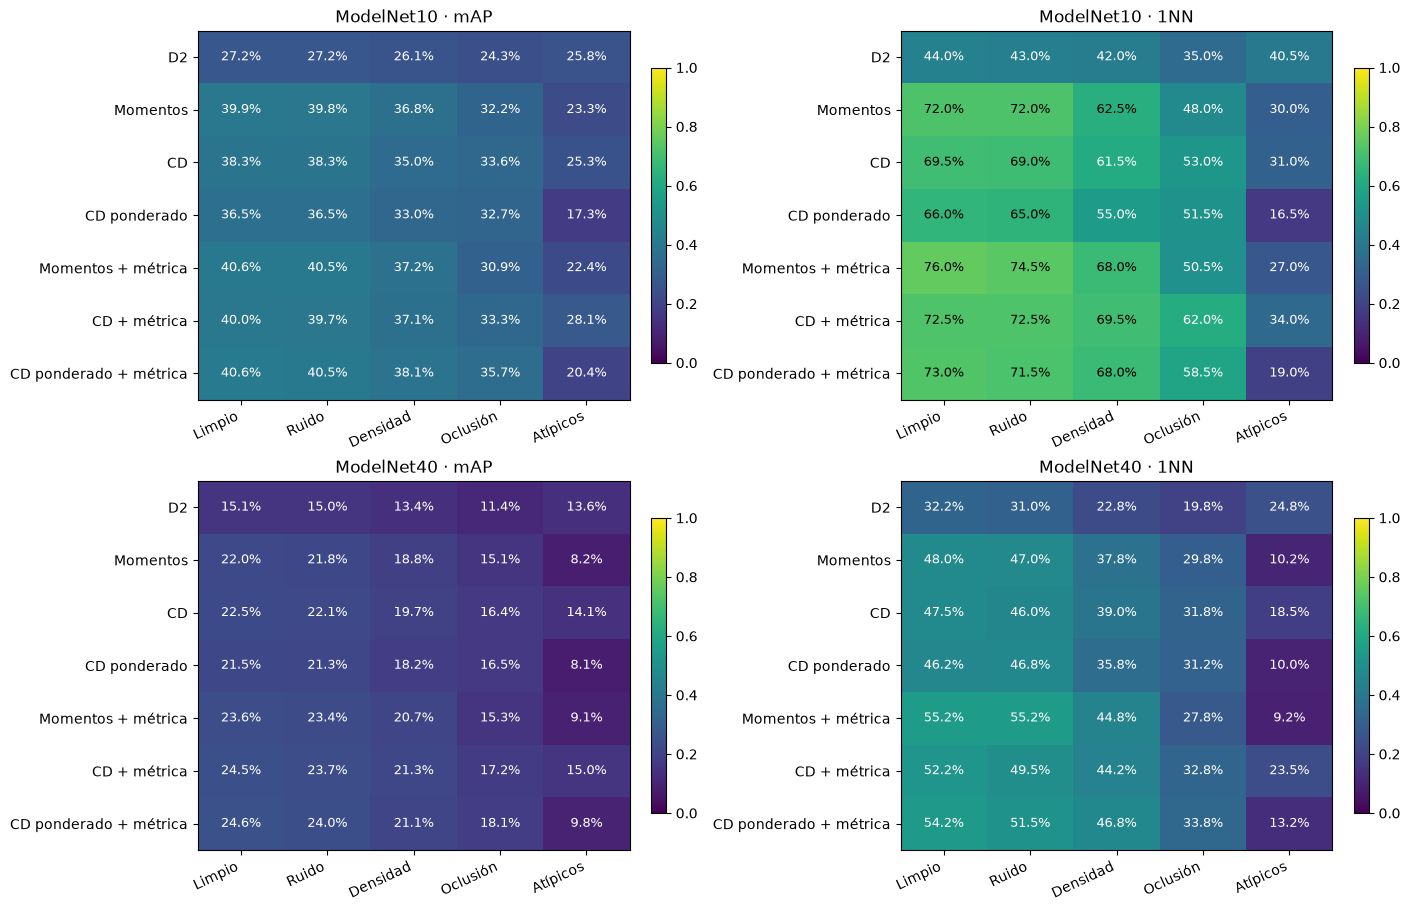

In [3]:
fig,axs=plt.subplots(2,2,figsize=(14,9),layout='constrained')
for i,ds in enumerate(DATASETS):
    for j,metric in enumerate(['mAP','1NN']):
        ax=axs[i,j]
        H=mine[mine.dataset.eq(ds)].pivot(index='method',columns='condition',values=metric).reindex(index=list(METHODS),columns=CONDITIONS)
        V=H.to_numpy(dtype=float,copy=True)
        im=ax.imshow(V,vmin=0,vmax=1,cmap='viridis',aspect='auto')
        for r,c in np.ndindex(V.shape):
            lum=np.dot(im.cmap(im.norm(V[r,c]))[:3],[.299,.587,.114])
            ax.text(c,r,f'{100*V[r,c]:.1f}%',ha='center',va='center',color='black' if lum>.5 else 'white',fontsize=9)
        ax.set_xticks(range(5),list(CN.values()),rotation=25,ha='right')
        ax.set_yticks(range(7),list(METHODS.values()))
        ax.set_title(f'{ds} · {metric}')
        fig.colorbar(im,ax=ax,shrink=.8)
save(fig,'07_modelnet_comparacion_corregida')

**3. Clasificación publicada.** Resultados contextuales de la literatura recopilada en la auditoría anterior. Se conservan URL y protocolo; los datos ausentes no se imputan. No se compara top-1 con mAP ni 1-NN. No se ha entrenado un SVM sobre CD en este cuaderno.

,method,year,protocol,ModelNet10,ModelNet40,source
0,FoldingNet,2018,SVM lineal,94.4,88.4,https://openaccess.thecvf.com/content_cvpr_201...
1,Latent-GAN,2018,SVM lineal,95.3,85.7,https://openaccess.thecvf.com/content_cvpr_201...
2,PointNet,2017,Supervisado,NaN,89.2,https://arxiv.org/abs/1612.00593
3,PointNet++,2017,Supervisado,NaN,91.9,https://arxiv.org/abs/1706.02413
4,DGCNN,2019,Supervisado,NaN,92.9,https://arxiv.org/abs/1801.07829
5,PointMLP,2022,Supervisado,NaN,94.1,https://arxiv.org/abs/2202.07123
6,Point-M2AE,2022,SVM lineal,NaN,92.9,https://arxiv.org/abs/2205.14401
7,I2P-MAE,2023,SVM lineal,NaN,93.4,https://openaccess.thecvf.com/content/CVPR2023...


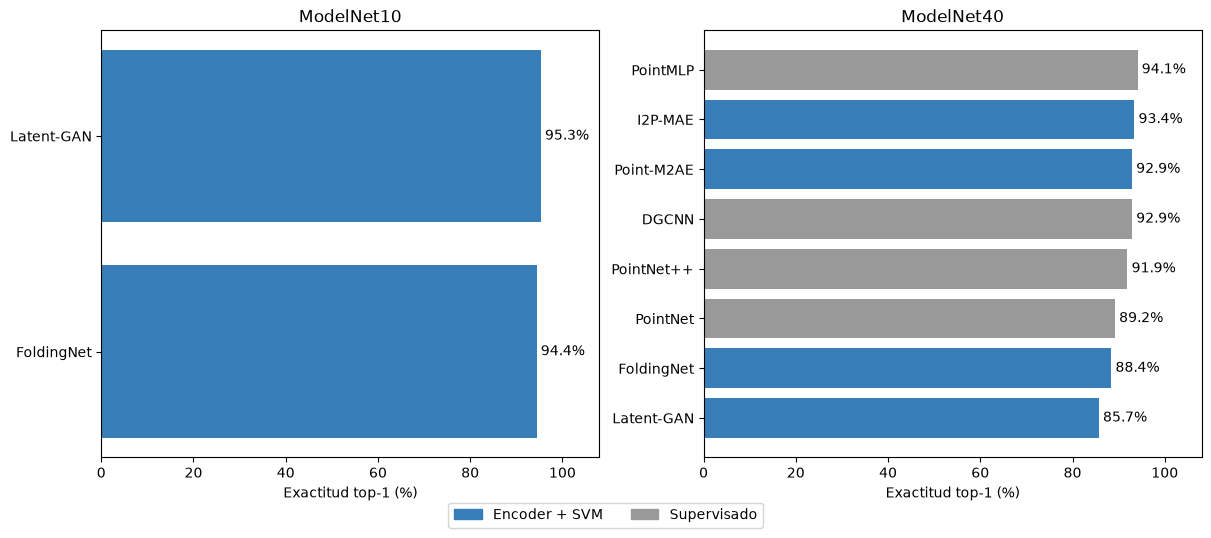

In [4]:
fold='https://openaccess.thecvf.com/content_cvpr_2018/papers/Yang_FoldingNet_Point_Cloud_CVPR_2018_paper.pdf'
literature=pd.DataFrame([
('FoldingNet',2018,'SVM lineal',94.4,88.4,fold),
('Latent-GAN',2018,'SVM lineal',95.3,85.7,fold),
('PointNet',2017,'Supervisado',np.nan,89.2,'https://arxiv.org/abs/1612.00593'),
('PointNet++',2017,'Supervisado',np.nan,91.9,'https://arxiv.org/abs/1706.02413'),
('DGCNN',2019,'Supervisado',np.nan,92.9,'https://arxiv.org/abs/1801.07829'),
('PointMLP',2022,'Supervisado',np.nan,94.1,'https://arxiv.org/abs/2202.07123'),
('Point-M2AE',2022,'SVM lineal',np.nan,92.9,'https://arxiv.org/abs/2205.14401'),
('I2P-MAE',2023,'SVM lineal',np.nan,93.4,'https://openaccess.thecvf.com/content/CVPR2023/html/Zhang_Learning_3D_Representations_From_2D_Pre-Trained_Models_via_Image-to-Point_Masked_CVPR_2023_paper.html'),
],columns=['method','year','protocol','ModelNet10','ModelNet40','source'])
literature.to_csv(OUT/'07_literatura_clasificacion.csv',index=False)
display(literature)
fig,axs=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,ds in zip(axs,DATASETS):
    t=literature.dropna(subset=[ds]).sort_values(ds)
    bars=ax.barh(t.method,t[ds],color=['#377eb8' if p=='SVM lineal' else '#999999' for p in t.protocol])
    ax.bar_label(bars,fmt='%.1f%%',padding=3);ax.set(xlim=(0,108),xlabel='Exactitud top-1 (%)',title=ds)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='#377eb8',label='Encoder + SVM'),Patch(color='#999999',label='Supervisado')],loc='lower center',bbox_to_anchor=(.5,-.06),ncol=2)
save(fig,'07_literatura_clasificacion')

**4. Recuperación publicada.** Valores de mAP de la tabla comparativa GPSP-DWRN (2021) y del estudio ResSANet (2021). Son referencias contextuales: las particiones, galerías, entradas y supervisión pueden diferir. No se usan para declarar superioridad estadística.

,method,ModelNet10,ModelNet40,source,origin
0,GPSP-DWRN,0.895000,0.858000,https://pmc.ncbi.nlm.nih.gov/articles/PMC8070544/,Literatura
1,GIFT,0.911200,0.819400,https://www.robots.ox.ac.uk/~tvg/publications/...,Literatura
2,DGCNN,NaN,0.853000,https://www.mdpi.com/1424-8220/21/9/3227,Literatura
3,CD,0.383049,0.224984,benchmarks/results/modelnet*_test.csv,Propio
4,CD + métrica,0.399552,0.244542,benchmarks/results/modelnet*_test.csv,Propio
5,CD ponderado,0.365492,0.215241,benchmarks/results/modelnet*_test.csv,Propio
6,CD ponderado + métrica,0.406359,0.246382,benchmarks/results/modelnet*_test.csv,Propio
7,D2,0.272121,0.151321,benchmarks/results/modelnet*_test.csv,Propio
8,Momentos,0.398547,0.220037,benchmarks/results/modelnet*_test.csv,Propio
9,Momentos + métrica,0.406102,0.236354,benchmarks/results/modelnet*_test.csv,Propio


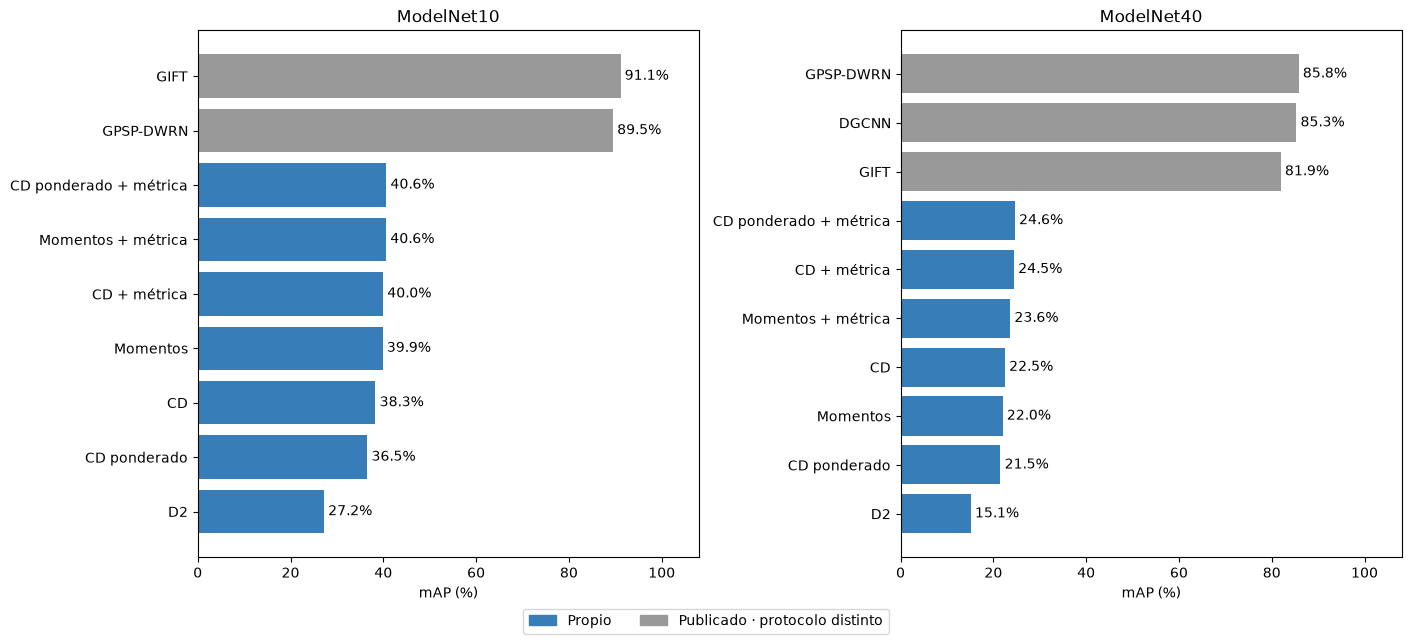

In [5]:
src='https://pmc.ncbi.nlm.nih.gov/articles/PMC8070544/'
retrieval=pd.DataFrame([
('GPSP-DWRN',.895,.858,src),
('GIFT',.9112,.8194,'https://www.robots.ox.ac.uk/~tvg/publications/2019/ued_cvpr.pdf'),
('DGCNN',np.nan,.853,'https://www.mdpi.com/1424-8220/21/9/3227'),
],columns=['method','ModelNet10','ModelNet40','source'])
retrieval['origin']='Literatura'
own=mine[mine.condition.eq('clean')].pivot(index='method_name',columns='dataset',values='mAP').reset_index().rename(columns={'method_name':'method'})
own['origin']='Propio';own['source']='benchmarks/results/modelnet*_test.csv'
comparison=pd.concat([retrieval,own],ignore_index=True)
comparison.to_csv(OUT/'07_comparacion_retrieval_literatura.csv',index=False)
display(comparison)
fig,axs=plt.subplots(1,2,figsize=(14,6),layout='constrained')
for ax,ds in zip(axs,DATASETS):
    t=comparison.dropna(subset=[ds]).sort_values(ds)
    bars=ax.barh(t.method,t[ds]*100,color=['#377eb8' if o=='Propio' else '#999999' for o in t.origin])
    ax.bar_label(bars,fmt='%.1f%%',padding=3);ax.set(xlim=(0,108),xlabel='mAP (%)',title=ds)
fig.legend(handles=[Patch(color='#377eb8',label='Propio'),Patch(color='#999999',label='Publicado · protocolo distinto')],loc='lower center',bbox_to_anchor=(.5,-.06),ncol=2)
save(fig,'07_comparacion_retrieval_dnn')

**5. Tabla final y trazabilidad.** No usar los antiguos PDF `07_contexto_dnn_vs_mi_*`: contienen selecciones incorrectas. La tabla nueva mantiene separadas las métricas y sus unidades. El siguiente experimento opcional es clasificación lineal de CD con particiones oficiales, no incluido aquí.

In [6]:
rows=[]
for _,r in mine[mine.condition.eq('clean')].iterrows():
    for metric in ['mAP','1NN']:
        rows.append([r.dataset,r.method,'Propio',metric,float(r[metric]),'Recuperación','benchmarks/results/'+r.dataset.lower()+'_test.csv'])
for _,r in literature.iterrows():
    for ds in DATASETS:
        if pd.notna(r[ds]): rows.append([ds,r.method,'Literatura','top1_accuracy',r[ds]/100,r.protocol,r.source])
for _,r in retrieval.iterrows():
    for ds in DATASETS:
        if pd.notna(r[ds]): rows.append([ds,r.method,'Literatura','mAP',r[ds],'Recuperación; protocolo externo',r.source])
final=pd.DataFrame(rows,columns=['dataset','method','origin','metric','value','protocol','source'])
final.to_csv(OUT/'07_tabla_comparacion_dnn_modelnet.csv',index=False)
display(final)
print('Finalizado:',OUT)

,dataset,method,origin,metric,value,protocol,source
0,ModelNet10,CD_U,Propio,mAP,0.383049,Recuperación,benchmarks/results/modelnet10_test.csv
1,ModelNet10,CD_U,Propio,1NN,0.695000,Recuperación,benchmarks/results/modelnet10_test.csv
2,ModelNet10,CD_W,Propio,mAP,0.365492,Recuperación,benchmarks/results/modelnet10_test.csv
3,ModelNet10,CD_W,Propio,1NN,0.660000,Recuperación,benchmarks/results/modelnet10_test.csv
4,ModelNet10,M_U,Propio,mAP,0.398547,Recuperación,benchmarks/results/modelnet10_test.csv
5,ModelNet10,M_U,Propio,1NN,0.720000,Recuperación,benchmarks/results/modelnet10_test.csv
6,ModelNet10,D2,Propio,mAP,0.272121,Recuperación,benchmarks/results/modelnet10_test.csv
7,ModelNet10,D2,Propio,1NN,0.440000,Recuperación,benchmarks/results/modelnet10_test.csv
8,ModelNet10,CD_U_metric,Propio,mAP,0.399552,Recuperación,benchmarks/results/modelnet10_test.csv
9,ModelNet10,CD_U_metric,Propio,1NN,0.725000,Recuperación,benchmarks/results/modelnet10_test.csv


Finalizado: /home/icantu24/Documents/PEF-CD/point-field/runs/tesis_figuras
